In [15]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib import font_manager

# --- 中文字体设置 -----------------------------------------------------------
# matplotlib 默认字体（DejaVu Sans）不含中文字形，因此标题/坐标轴里的中文会出现
# “Glyph 30452 ... missing from font(s)” 警告，并显示成方框。
# Pick the first font that is actually installed on this machine.
# 按优先级从本机已安装的字体中挑选可用的中文字体（未安装的自动跳过）。
CJK_FONTS = [
    "PingFang SC",  # macOS default / macOS 默认中文字体
    "Hiragino Sans GB",  # macOS
    "Heiti SC",  # macOS
    "Songti SC",  # macOS
    "Arial Unicode MS",  # macOS
    "Noto Sans CJK SC",  # Linux (deb: fonts-noto-cjk)
    "WenQuanYi Zen Hei",  # Linux
    "Microsoft YaHei",  # Windows
    "SimHei",  # Windows
]
_installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.sans-serif"] = [f for f in CJK_FONTS if f in _installed_fonts] + [
    "DejaVu Sans"
]  # DejaVu Sans as the final fallback / 最后保底用 DejaVu Sans
# keep the ASCII minus sign, otherwise U+2212 may be a missing glyph too
# 使用 ASCII 减号，否则 U+2212 也可能缺字形
plt.rcParams["axes.unicode_minus"] = False

In [16]:
# 检查数据文件（兼容两种启动方式：从仓库根目录启动 Jupyter，或直接打开本 notebook）
# Locate the data file (works whether Jupyter is launched from the repo root or the project folder)
_candidates = [
    Path.cwd() / "AB_Test_Results.csv",                          # 仓库根目录 / repo root
    Path.cwd() / "20261003_AB_Test" / "AB_Test_Results.csv",      # 从仓库根进入项目目录 / project folder under repo root
]
DATA_FILE = next((p for p in _candidates if p.exists()), None)
assert DATA_FILE is not None and DATA_FILE.exists(), (
    "未找到 AB_Test_Results.csv，请将其放到本 notebook 同目录或仓库根目录。 "
    "AB_Test_Results.csv not found; put it next to this notebook or at the repo root."
)
print(f"Data file / 数据文件: {DATA_FILE}")


## 0. 加载数据并进行初步检查

In [17]:
df = pd.read_csv(DATA_FILE, header=0)

# Format Fix: 'user_id' is categorical, not number
# 格式修正：'user_id' 是分类变量，不是数值
df["USER_ID"] = df["USER_ID"].astype(str)

# Inspect the data overview (column types, non-null counts, etc.)
# 查看数据概况（列类型、非空数量等）
print("\n# Info")
display(df.info())


# column variables
# 列名变量（避免硬编码字符串，统一通过 Col 引用）
class Col:
    USER_ID = "USER_ID"
    VARIANT_NAME = "VARIANT_NAME"
    REVENUE = "REVENUE"


# Descriptive statistics
# 查看描述性统计
print("\n# Summary")
display(df.describe(include="all"))

# Distinct experiment groups (e.g. control / variant)
# 查看实验分组类别（如 control / variant）
print("\n# Variant Name")
print(df[Col.VARIANT_NAME].unique())


# Info
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   USER_ID       10000 non-null  str    
 1   VARIANT_NAME  10000 non-null  str    
 2   REVENUE       10000 non-null  float64
dtypes: float64(1), str(2)
memory usage: 234.5 KB


None


# Summary


,USER_ID,VARIANT_NAME,REVENUE
count,10000,10000,10000.000000
unique,6324,2,NaN
top,4879,variant,NaN
freq,6,5016,NaN
mean,NaN,NaN,0.099447
std,NaN,NaN,2.318529
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,0.000000
75%,NaN,NaN,0.000000



# Variant Name
<StringArray>
['variant', 'control']
Length: 2, dtype: str


In [18]:
# setup duckdb so we can use standard SQL to manipulate data
db = duckdb.connect()

# attach to duckdb
_ = db.register("df", df)

## 1. 定义分析目标

研究 `variant`（测试组）相比 `control`（对照组）对 `revenue`（收入）产生了什么影响。

## 2. 检查实验卫生(Experiment Hygiene)

在相信这个 A/B 实验的任何结论之前，我们先验证实验本身是否可靠：
随机分组有没有被破坏、两组之间是否具有可比性。
如果实验本身有问题，再小的 p 值也救不回来。

### 2.1 定义实验单元

任何A/B测试都涉及三种颗粒度，如果不明确区分定义，有可能造成概念混淆，导致分析结论混乱：

- **Unit of Randomization (UR, 随机化单元/分流主体)**: 指分配到不同组别所用的实体单位。（可能是不同的用户`USER_ID`，可能是来自不同地区`REGION_ID`）。
- **Unit of Observation (UO, 观测单元)**: 观测收集到的数据中记录的颗粒度（`(user_id, device_id, timestamp)`）。
- **Unit of Analysis (UA, 分析单元)**: 在数据分析中实际使用的数据颗粒度。

> 这么说比较抽象，其实可以把这三个所谓“单元“理解成维度建模里面的维度/或者关系型数据库里的“主键”。

UR的定义很大程度上决定了AB检测的分析范畴，在数据预处理阶段我们需要保证将
绝大多数实验中会要求这三者保持一致，分流主体（UR）和分析单元（UA）

把这三者显式地定义，是有效分析的前提。

如果三者不一致（“分流主体是用户按用户随机分组，却按 session 或曝光进行分析”），
观测数据和现象之间就的关联就不再单纯反映预设的问题。



In [19]:
# Unit identification / 实验单元定义
# UR (Unit of Randomization) 随机化单元/分流主体 : user / 用户 (USER_ID)
# UO (Unit of Observation)   观测单元           : one row of the raw table / 原始表的一行（发现存在重复记录）
# UA (Unit of Analysis)      分析单元           : user / 用户 (USER_ID)

# --- UO 的不一致：这张表不是“一行一个用户” ---------------------------------
n_rows = len(df)
n_users = df[Col.USER_ID].nunique()
print(f"rows / 记录行数 : {n_rows}")
print(f"distinct users / 去重用户数 : {n_users}")

# 每个用户各占了多少行？
rows_per_user = df.groupby(Col.USER_ID).size().rename("n_rows")
display(rows_per_user.value_counts().sort_index().rename("n_users").to_frame())

rows / 记录行数 : 10000
distinct users / 去重用户数 : 6324


,n_users
n_rows,
1,3664
2,1890
3,570
4,159
5,36
6,5


### 2.1 检查个体处理稳定性(SUTVA)

> SUTVA: Stable Unit Treatment Value Assumption

SUTVA 要求：某个用户的分组不会影响其他用户的结果，且每种处理只存在一个版本。

,arm,n_users
2,both,1541
1,control,2390
0,variant,2393


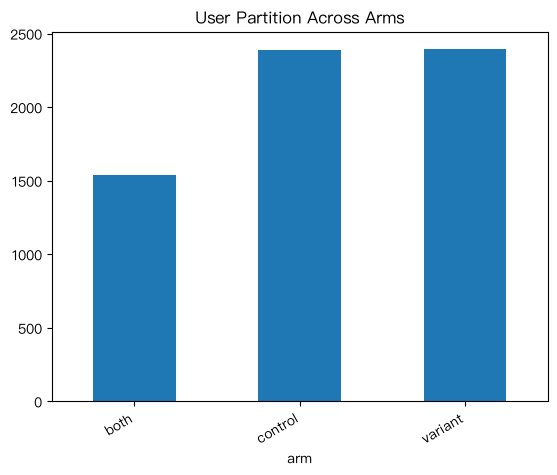

In [20]:
# SUTVA
# Find user with more than one variants
q = """
with user_arms as (
    select user_id,
           count(distinct variant_name) as n_arms,
           min(variant_name) as only_arm
    from df
    group by user_id
)
select case
           when n_arms > 1 then 'both'
           else only_arm
       end as arm,
       count(*) as n_users
from user_arms
group by arm
"""
variant_partition = db.sql(q).df().sort_values(by="n_users")
display(variant_partition)


ax = variant_partition.plot.bar(
    x="arm", y="n_users", legend=False, title="User Partition Across Arms"
)
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")

### 2.2 检查样本比例偏差（SRM）- 卡方拟合优度检验($\chi^2$ Goodness-of-Fit Test)

> SRM: Sample Ratio Mismatch

样本比例失衡（SRM）是指 `control` / `variant` 的实际样本比例偏离了预期比例（例如 50/50）。
这通常是由于后端流量分发或数据收集过程出错。

在 A/B 测试中常用的样本比例偏差检查手段是卡方拟合优度检验($\chi^2$ Goodness-of-Fit Test)。

- 原假设$H_0$: 分流机制正常，实际分配比例符合预设规则
- 备择假设$H_\alpha$: 分流机制不正常，实际分配比例偏离了预设规则

In [21]:
# --- 卡方检验 ---------------------
srm = (
    variant_partition.loc[
        variant_partition["arm"].isin(["control", "variant"])
    ]  # remove users with both treatments / 剔除同时出现在两个实验组的用户
    .set_index("arm")["n_users"]
    .reindex(["control", "variant"])  # deterministic order / 固定顺序，保证结果可复现
)
observed = srm.to_numpy(dtype=float)
n_clean = int(observed.sum())
expected = np.full(2, n_clean / 2)  # assumed 50/50 allocation / 假设按 50/50 分配

# 卡方（Chi^2)拟合优度检验

# 自由度 df = k - 1 - m
k = 2  # 2个分箱区间
m = 0  # 无估计参数
dof = k - 1 - m
chi2_stat = sps.chisquare(observed, f_exp=expected).statistic
p_value = sps.chi2.sf(chi2_stat, df=dof)

print("\nSRM：卡方拟合优度检验（对照组 vs 测试组）")
print(f"n={n_clean}")
print(f"理论值 : {expected[0]:.1f} control, {expected[0]:.1f} variant")
print(f"实际值 : {srm['control']:.1f} control, {srm['variant']:.1f} variant")

print(f"chi2 = {chi2_stat:.4f}, df = {dof}, p-value = {p_value:.4f}")

if p_value >= 0.05:
    verdict_zh = "无样本比例偏差（SRM） —— 各组样本量与预期的 50/50 分配一致"
elif p_value >= 0.001:
    verdict_zh = "风险：样本比例偏差（SRM） —— 需先排查确认，再继续后续分析"
else:
    verdict_zh = "警告：样本比例偏差（SRM） —— 各组样本比例严重偏离了预设的分配比例"
print(f"结论 : {verdict_zh}")


SRM：卡方拟合优度检验（对照组 vs 测试组）
n=4783
理论值 : 2391.5 control, 2391.5 variant
实际值 : 2390.0 control, 2393.0 variant
chi2 = 0.0019, df = 1, p-value = 0.9654
结论 : 无样本比例偏差（SRM） —— 各组样本量与预期的 50/50 分配一致


## 3. 调查数据分布特征 - 零膨胀

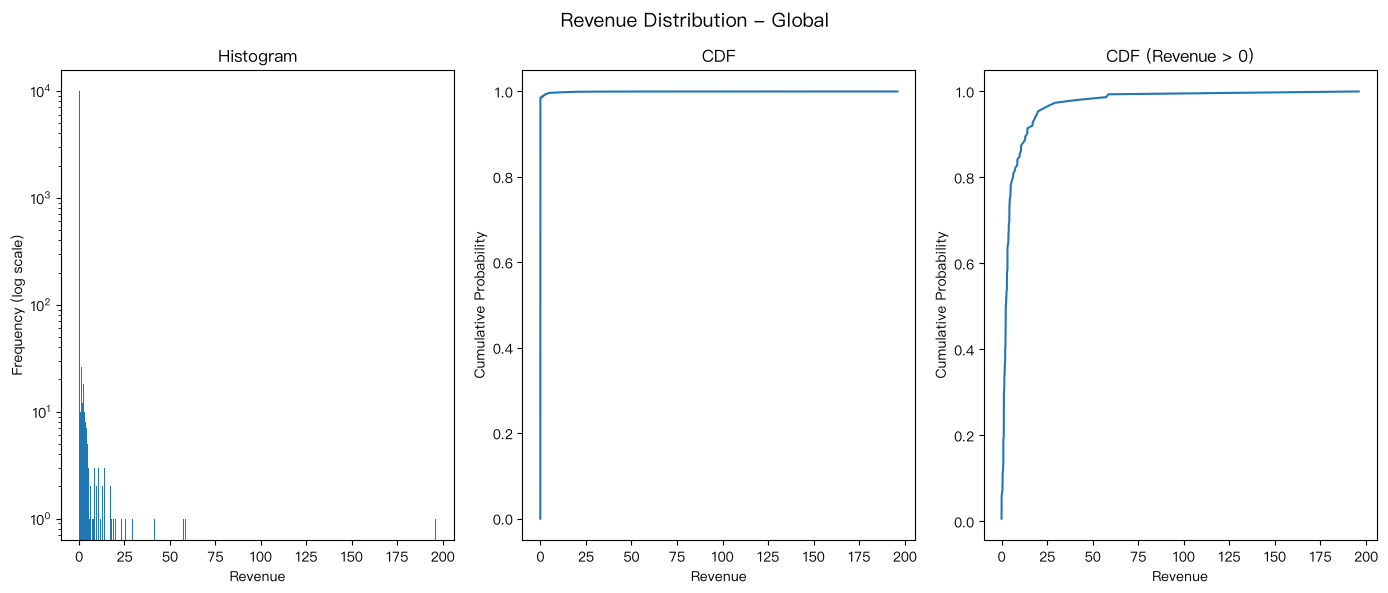


== Global ==
Proportion of revenue = 0 / 零收入占比 : 98.48%


In [22]:
# 定义一个可复用的绘图函数，供后面的分组复用。
def plot_revenue_distribution(
    s: pd.Series, label: str, figsize: tuple = (6, 3)
) -> None:
    """Plot histogram / empirical CDF / CDF(revenue > 0) and print summary stats.

    绘制直方图 / 经验 CDF / 收入 > 0 的 CDF，并打印汇总统计量。
    """
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)
    fig.suptitle(f"Revenue Distribution - {label}", fontsize=14)

    # histogram (log y-axis: the vast majority of users have zero revenue)
    # 直方图（y 轴取对数：绝大多数用户的收入为 0）
    bins = np.arange(0, s.max() + 0.5, 0.5)
    s.plot.hist(bins=bins, title="Histogram", ax=ax1, logy=True)
    ax1.set_xlabel("Revenue")
    ax1.set_ylabel("Frequency (log scale)")

    # empirical CDF
    # 经验累积分布函数
    s_sorted = np.sort(s)
    cdf = np.arange(1, len(s_sorted) + 1) / len(s_sorted)
    pd.Series(cdf, index=s_sorted).plot.line(title="CDF", ax=ax2)
    ax2.set_xlabel("Revenue")
    ax2.set_ylabel("Cumulative Probability")

    # CDF zoomed to revenue > 0, to inspect the tail
    # 只看收入 > 0 的 CDF，用于观察长尾部分
    pos_sorted = np.sort(s.loc[s > 0])
    pos_cdf = np.arange(1, len(pos_sorted) + 1) / len(pos_sorted)
    pd.Series(pos_cdf, index=pos_sorted).plot.line(title="CDF (Revenue > 0)", ax=ax3)
    ax3.set_xlabel("Revenue")
    ax3.set_ylabel("Cumulative Probability")

    plt.tight_layout()
    plt.show()

    # summary stats
    # 汇总统计量
    print(f"\n== {label} ==")
    print(f"Proportion of revenue = 0 / 零收入占比 : {(s == 0).mean():.2%}")


plot_revenue_distribution(df[Col.REVENUE], "Global", figsize=(14, 6))

group both count / 两组用户记录数 : 3930
group control count / 对照组记录数 : 3026
group variant count / 测试组记录数 : 3044


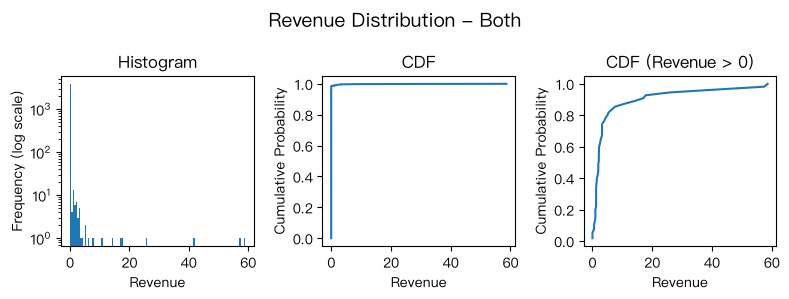


== Both ==
Proportion of revenue = 0 / 零收入占比 : 98.60%


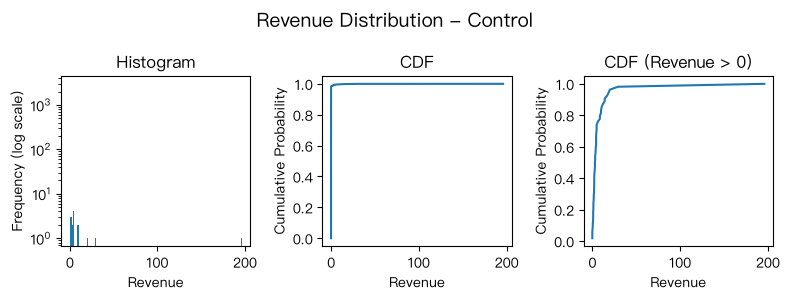


== Control ==
Proportion of revenue = 0 / 零收入占比 : 98.22%


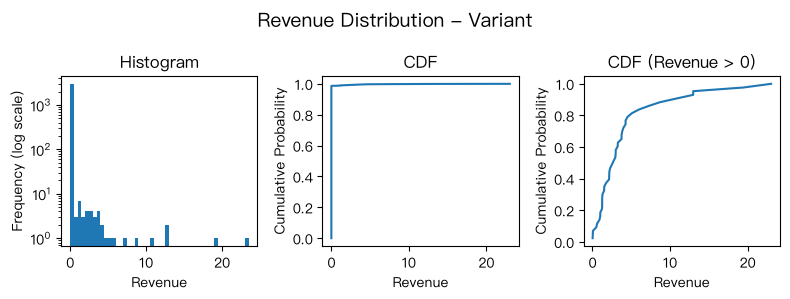


== Variant ==
Proportion of revenue = 0 / 零收入占比 : 98.59%


In [23]:
# 按分组查看收入分布（'both' / 'control' / 'variant'）。

variant_count = df.groupby(Col.USER_ID)[Col.VARIANT_NAME].nunique()
both_users = variant_count[variant_count > 1].index

# Groupings
# 分组
group_both = df.loc[df[Col.USER_ID].isin(both_users), Col.REVENUE]
print(f"group both count / 两组用户记录数 : {group_both.count()}")

group_control = df.loc[
    ~df[Col.USER_ID].isin(both_users) & (df[Col.VARIANT_NAME] == "control"),
    Col.REVENUE,
]
print(f"group control count / 对照组记录数 : {group_control.count()}")

group_variant = df.loc[
    ~df[Col.USER_ID].isin(both_users) & (df[Col.VARIANT_NAME] == "variant"),
    Col.REVENUE,
]
print(f"group variant count / 测试组记录数 : {group_variant.count()}")

# 三个分组合起来必须等于整个数据集
assert (
    group_both.count() + group_control.count() + group_variant.count()
    == df[Col.REVENUE].count()
)


# 复用上面定义的绘图函数，逐组绘制
fig_size = (8, 3)
plot_revenue_distribution(group_both, "Both", fig_size)
plot_revenue_distribution(group_control, "Control", fig_size)
plot_revenue_distribution(group_variant, "Variant", fig_size)

## 4. 预处理
  - SUTVA问题 - 剔除Both
  - UO的不一致（group sum）

In [24]:
# --- Step 0 · data cleaning & analysis datasets --------------------------
df_dedup = df.drop_duplicates(
    subset=[Col.USER_ID, Col.VARIANT_NAME, Col.REVENUE]
).copy()

# 1) drop "BOTH" user, users having both treatments
q = """
select user_id, count(distinct variant_name) variant_count
from df 
group by user_id
having count(distinct variant_name) > 1
"""

user_more_than_one_variants = db.sql(q).df()
db.register("user_more_than_one_variants", user_more_than_one_variants)
print(
    "Users More Than One Variants count:\n",
    user_more_than_one_variants.count(axis=0),
)

# 2) keep single-arm (clean) users only
both_ids = set(user_more_than_one_variants[Col.USER_ID])
df_clean = df_dedup.loc[~df_dedup[Col.USER_ID].isin(both_ids)].copy()

# 3) aggregate rows -> one record per USER (primary analysis unit)
clean_user = (
    df_clean.groupby(Col.USER_ID)
    .agg(arm=(Col.VARIANT_NAME, "first"), revenue=(Col.REVENUE, "sum"))
    .reset_index()
)
clean_user["converted"] = (clean_user["revenue"] > 0).astype(int)
print(f"\nclean users: {len(clean_user)}")
print("\n", clean_user.head(3), "\n")
print(clean_user["arm"].value_counts().to_string())

Users More Than One Variants count:
 USER_ID          1541
variant_count    1541
dtype: int64

clean users: 4783

   USER_ID      arm  revenue  converted
0    1000  control      0.0          0
1    1002  control      0.0          0
2    1003  control      0.0          0 

arm
variant    2393
control    2390


## 5. 两阶段分析(Two-Part Analysis)

### 5.1 指标拆解：把"每用户平均收入"拆成「转化」×「客单」

> 为什么要拆？因为 revenue 是典型的 **zero-inflated（零膨胀）+ right-skewed（右偏）** 混合分布：
>
> - 大量用户 revenue = 0（未转化），在 0 处形成一个“尖峰”（point mass）；
> - 少数付费用户 revenue > 0，且呈长尾右偏。
>
> 用单一分布同时刻画“是否付费”和“付多少”这两件事会互相干扰；拆成两个子问题后，各自的分布更干净、模型假设更贴合。

每用户平均收入（ARPU, Average Revenue Per User）可以拆解为两个因子的乘积：

$$
\text{ARPU} = \underbrace{P(\text{converted})}_{\text{Conversion Rate}} \times
\underbrace{\mathbb{E}[\text{revenue} \mid \text{converted}]}_{\text{ARPPU}}
$$

- $P(\text{converted})$：**Conversion Rate（转化率）**
- $\mathbb{E}[\text{revenue} \mid \text{converted}]$：**ARPPU（Average Revenue Per Paying User，付费用户平均收入）**

采用 **Two-Part Analysis（两阶段分析）**：
- **Part 1**：先看 Variant 是否改变 **转化率**；
- **Part 2**：再在**已转化**的子样本内，看 Variant 是否改变 **付费金额**。

### 5.2 为什么转化率用 Bernoulli 分布

- 因变量 `converted` 取值 $\{0, 1\}$，是二值结果，其自然分布就是 **Bernoulli 分布**。
- 均值 $p_i$ 必须落在 $[0, 1]$ 内，故配合 **canonical link（典型连结函数）logit**，即 logistic regression，把取值域映射到 $(-\inf, \inf)$。
- 系数 $\beta_1$ 直接给出 **log odds ratio**，$\exp(\beta_1)$ 即 **Odds Ratio (OR)**，方向与显著性都直观可解释。

### 5.3 为什么 ARPPU（付费金额）用 Gamma 分布

- 在“已转化”条件下，revenue **严格为正、连续、右偏长尾**，且**方差随均值增大而增大**。
- **Gamma 分布**定义域为 $(0, \infty)$，天然右偏，且 $\operatorname{Var}(Y) = \phi \, \mu^2$（方差正比于均值的平方），与消费金额的 mean–variance 关系吻合。
- 采用 **log link**：既保证 $\mu > 0$，又给出更好理解的解释——$\exp(\beta_2)$ 是 Variant 与 Control 的期望消费之比（**Spend Ratio**）。

In [25]:
# Part 1 · 转化率分析 (GLM with Bernoulli Distribution)
#
# 设计上说 Bernoulli、代码里却写 Binomial，并不矛盾：
#
# 1. Bernoulli 是 Binomial 在 n = 1 时的特例。
#    Binomial(n, p) 表示 n 次独立试验中的成功次数，取值 {0, 1, ..., n}；
#    当每个观测只做 1 次试验（n = 1，即每个用户只有“转化 / 未转化”一种结果）时，
#    取值退化为 {0, 1}，正是 Bernoulli(p)：
#        Binomial(n = 1, p) ≡ Bernoulli(p)
#
# 2. statsmodels 的 GLM API 没有单独的 Bernoulli 家族：
#    sm.families 只提供 Binomial；在 n = 1 时，其 log-likelihood、variance
#    function 与 IRLS 权重与 Bernoulli 完全相同。

logit_m = smf.glm(
    "converted ~ C(arm)", data=clean_user, family=sm.families.Binomial()
).fit()
b1 = logit_m.params["C(arm)[T.variant]"]
b1_ci = logit_m.conf_int().loc["C(arm)[T.variant]"]
or_ci = np.exp(b1_ci)

print("== Convert Rate Analysis Statistics:")
print(f"variant coefficient beta_1 = {b1:+.3f}   -> Odds Ratio (OR) = {np.exp(b1):.3f}")
print(f"beta_1 95% CI              = [{b1_ci[0]:+.3f}, {b1_ci[1]:+.3f}]")
print(f"OR 95% CI                  = [{or_ci[0]:.3f}, {or_ci[1]:.3f}]")
print(f"p-value                    = {logit_m.pvalues['C(arm)[T.variant]']:.3f}")

print("""
Odds Ratio (OR) 的关键值为1:
- OR = 1: Variant has no effect on conversion odds.
- OR > 1: Variant increases conversion rate.
- OR < 1: Variant decreases conversion rate.
""")

# Part 1 conclusion — interpret OR, its 95% CI, and significance
or_hat = np.exp(b1)
p_val = logit_m.pvalues["C(arm)[T.variant]"]

# Effect direction
if or_hat > 1:
    direction = "Variant 提升转化率"
elif or_hat < 1:
    direction = "Variant 降低转化率"
else:
    direction = "Variant 对转化率无影响"

# Significance: does the 95% CI exclude OR = 1?
significant = (or_ci[0] > 1) or (or_ci[1] < 1)
significance = (
    "在 5% 显著性水平下显著（95% CI 不包含 1）"
    if significant
    else "在 5% 显著性水平下不显著（95% CI 包含 1）"
)

print("== 结论 ==")
print(f"- 显著性：{significance}")
if significant:
    print(
        f"- 解读：Variant 使转化 odds 变为对照组的 {or_hat:.3f} 倍"
        f"（约 {(or_hat - 1) * 100:+.1f}%），该差异在统计上显著。"
    )
else:
    print("- 解读：无法拒绝 OR = 1 的原假设，当前证据不足以认为 Variant 改变了转化率。")
print(f"- 效应方向：{direction}")

== Convert Rate Analysis Statistics:
variant coefficient beta_1 = -0.258   -> Odds Ratio (OR) = 0.773
beta_1 95% CI              = [-0.665, +0.150]
OR 95% CI                  = [0.514, 1.161]
p-value                    = 0.215

Odds Ratio (OR) 的关键值为1:
- OR = 1: Variant has no effect on conversion odds.
- OR > 1: Variant increases conversion rate.
- OR < 1: Variant decreases conversion rate.

== 结论 ==
- 显著性：在 5% 显著性水平下不显著（95% CI 包含 1）
- 解读：无法拒绝 OR = 1 的原假设，当前证据不足以认为 Variant 改变了转化率。
- 效应方向：Variant 降低转化率


---

#### 附：转化率分析的完整构建说明

> 广义线性模型（GLM）分析框架

对用户 $i$，令 $Y_i$ 表示其转化情况，令 $X_i$ 表示其所属处理组：

$$
\begin{align*}
Y_i &= \begin{cases} 1 & \text{if user } i \text{ convert to payer} \\ 0 &
\text{if user } i \text{ does not convert to payer} \end{cases} \\[1.5em]
X_i &= \begin{cases} 1 & \text{if user } i \text{ is in the variant arm} \\ 0 &
\text{if user } i \text{ is in the control arm} \end{cases}
\end{align*}
$$

**分布选择**

$$Y_i \mid X_i \sim \operatorname{Bernoulli}(p_i)$$

- $p_i = \mathbb{E}[Y_i \mid X_i] = P(Y_i = 1 \mid X_i) \in [0, 1]$ :
  在给定 $X_i$ 的条件下发生转化的概率（Probability of Conversion）

**线性预测子与连结函数（Linear predictor and Link Function）**

$$\ln\left(\frac{p_i}{1 - p_i}\right) = \eta_i = \beta_0 + \beta_1 X_i$$

- 我们将 "$\frac{p}{1-p}$" 这种形式称为概率 $p$ 的 "odds"（几率），记作 $\text{odds}
(p)$
- 我们将 "$\ln\left(\frac{p}{1 - p}\right)$" 这种形式称为概率 $p$ 的 "log-odds"（对数几率）或 "logit"，记作 $\operatorname{logit}(p)$



$$
\begin{align*}
X &= \begin{cases} 1 & \text{若用户属于测试组(Variant)} \\ 0 & \text{若用户属于对照组(Control)} \end{cases}
\end{align*}
$$

$$\text{logit}(p) = \beta_0 + \beta_1 X$$

因此，给定一个概率 $p$，我们通过下式将其取值范围从 $[0,1]$ 映射到 $(-\inf, \inf)$：

$$p \in [0, 1] \to \text{odds}(p) \in [0, \inf) \to \text{logit}(p) \in (-\inf,
\inf)$$

**系数的含义**

**$\beta_0$**

对于对照组（Control Arm，$X_i = 0$）：

$$
\begin{align*}
\ln(\text{Odds}_{\text{control}}) &= \beta_0 + \beta_1 \cdot 0 = \beta_0 \\[1.5em]
\text{Odds}_{\text{control}} &= \exp(\beta_0)
\end{align*}
$$

$\beta_0$ 表示对照组（control group）中转化的 log-odds（对数几率）。

- $\beta_0 = 0 \implies \text{Odds}_{\text{control}} = 1 \implies
  p_\text{control} = 0.5$
- $\beta_0 \to \inf \implies p_\text{control} \to 1$
- $\beta_0 \to -\inf \implies p_\text{control} \to 0$

**$\beta_1$**

对于测试组（Variant Arm，$X_i = 1$）：

$$ \begin{align*} \ln(\text{Odds}_{\text{variant}}) &= \beta_0 + \beta_1(1) =
\beta_0 + \beta_1 \\[1.5em] \ln(\text{Odds}_{\text{variant}}) - \ln(\text{Odds}
_{\text{control}}) &= (\beta_0 + \beta_1) - \beta_0 = \beta_1 \\[1.5em]
\ln\left(\frac{\text{Odds}_{\text{variant}}}{\text{Odds}_{\text{control}}}\right)
&= \beta_1\\[1.5em] \frac{\text{Odds}_{\text{variant}}}{\text{Odds}
_{\text{control}}} &= \exp(\beta_1) \end{align*} $$

我们给复合项 $\frac{\text{Odds}_{\text{variant}}}{\text{Odds}
_{\text{control}}}$ 起一个名字：**Odds Ratio (OR)**（几率比）

$$\text{OR} = \frac{\text{Odds}_{\text{variant}}}{\text{Odds}_{\text{control}}}
= \exp(\beta_1)$$

> $p \propto \text{Odds}$，$\text{Odds}$ 越大意味着 $p$ 越大

- $\beta_1 = 0 \to \text{OR} = 1 \to \text{Odds}_{\text{variant}} = \text{Odds}_{\text{control}}$: Variant 对转化的 odds（几率）没有影响。
- $\beta_1 > 0 \to \text{OR} > 1 \to \text{Odds}_{\text{variant}} > \text{Odds}_{\text{control}}$: Variant 提高转化率。
- $\beta_1 < 0 \to \text{OR} < 1 \to \text{Odds}_{\text{variant}} < \text{Odds}_{\text{control}}$: Variant 降低转化率。

In [26]:
# Part 2 · 付费用户平均支付金额(ARPPU)分析 (Gamma, log link)
payers = clean_user.loc[clean_user["converted"] == 1].copy()
gamma_m = smf.glm(
    "revenue ~ C(arm)",
    data=payers,
    family=sm.families.Gamma(link=sm.families.links.Log()),
).fit()
b1 = gamma_m.params["C(arm)[T.variant]"]
b1_ci = gamma_m.conf_int().loc["C(arm)[T.variant]"]
ratio_ci = np.exp(b1_ci)

print("\n=== Part 2 ARPPU Analysis Statistics")
print(
    f"variant coefficient beta_1 = {b1:+.3f}   -> Spend Ratio (SR) = {np.exp(b1):.3f}"
)
print(f"beta_1 95% CI              = [{b1_ci[0]:+.3f}, {b1_ci[1]:+.3f}]")
print(f"SR 95% CI                  = [{ratio_ci[0]:.3f}, {ratio_ci[1]:.3f}]")
print(f"p-value                    = {gamma_m.pvalues['C(arm)[T.variant]']:.3f}")

print("""
Spend Ratio (SR) 支付金额比的关键值为1:
- SR = 1: 两组平均消费相同。
- SR < 1: Variant 组的消费低于 Control 组。
- SR > 1: Variant 组的消费高于 Control组。
""")

# Part 2 conclusion — interpret Spend Ratio (SR), its 95% CI, and significance
# (pi answer)
sr_hat = np.exp(b1)
p_val2 = gamma_m.pvalues["C(arm)[T.variant]"]

# Effect direction
if sr_hat > 1:
    direction = "Variant 组付费用户平均消费高于 Control 组（ARPPU 提升）"
elif sr_hat < 1:
    direction = "Variant 组付费用户平均消费低于 Control 组（ARPPU 下降）"
else:
    direction = "两组付费用户平均消费相同（ARPPU 无差异）"

# Significance: does the 95% CI exclude SR = 1?
significant2 = (ratio_ci[0] > 1) or (ratio_ci[1] < 1)
significance2 = (
    "在 5% 显著性水平下显著（95% CI 不包含 1）"
    if significant2
    else "在 5% 显著性水平下不显著（95% CI 包含 1）"
)

print("== 结论 ==")
print(f"- 显著性：{significance2}")
if significant2:
    print(
        f"- 解读：Variant 组付费用户平均消费为 Control 组的 {sr_hat:.3f} 倍"
        f"（约 {(sr_hat - 1) * 100:+.1f}%），该差异在统计上显著。"
    )
else:
    print("- 解读：无法拒绝 SR = 1 的原假设，当前证据不足以认为 Variant 改变了 ARPPU。")
print(f"- 效应方向：{direction}")


=== Part 2 ARPPU Analysis Statistics
variant coefficient beta_1 = -0.713   -> Spend Ratio (SR) = 0.490
beta_1 95% CI              = [-1.689, +0.262]
SR 95% CI                  = [0.185, 1.300]
p-value                    = 0.152

Spend Ratio (SR) 支付金额比的关键值为1:
- SR = 1: 两组平均消费相同。
- SR < 1: Variant 组的消费低于 Control 组。
- SR > 1: Variant 组的消费高于 Control组。

== 结论 ==
- 显著性：在 5% 显著性水平下不显著（95% CI 包含 1）
- 解读：无法拒绝 SR = 1 的原假设，当前证据不足以认为 Variant 改变了 ARPPU。
- 效应方向：Variant 组付费用户平均消费低于 Control 组（ARPPU 下降）


---

#### 附：付费用户平均支付金额分析的完整构建说明

> 广义线性模型（GLM）分析框架

对每个 revenue $Y_i > 0$ 的付费用户 $i$，令 $X_i$ 表示其所属处理组：

$$X_i = \begin{cases} 1 & \text{if user } i \text{ is in the variant arm} \\ 0 &
\text{if user } i \text{ is in the control arm} \end{cases}$$

**分布选择**

$$Y_i \mid (Y_i > 0, X_i) \sim \operatorname{Gamma}\left(\text{shape} = \frac{1}
{\phi},\, \text{scale} = \phi \mu_i\right)$$

- $\mu_i = E[Y_i \mid Y_i > 0, X_i]$，表示在给定“付费用户处理”条件下的期望支付金额。
- $\phi$ 是离散度参数（dispersion parameter，由数据拟合得到）。

> 选择Gamma分布的原因
> - **Positive Support（正支撑集）:** revenue $Y_i > 0$
> - **Right-Skew and Heavy Tails（右偏与厚尾）:** 大量小额购买，以及少量极其巨大的
  "whale"（鲸鱼/大额）订单。
> - **Mean-Variance Relationship（均值-方差关系）:** 方差随均值增大——更高的支付金额伴随更大的离散度。Gamma 分布假设 $\operatorname{Var}(Y \mid X) = \phi \mu^2$，即方差与均值成比例（比例常数为 $\phi$)，符合实际业务场景。


**线性预测子与连结函数（Linear predictor and Link Function）**

$$ \begin{align*} \ln(\mu_i) &= \eta_i = \beta_0 + \beta_1 X_i \\[1.5em] \mu_i
&= \exp(\beta_0 + \beta_1 X_i) \end{align*} $$

$$\ln(\mu) = \beta_0 + \beta_1 X $$

---

**为什么用 Log Link（`link=sm.families.links.Log()` , $\ln(\mu_i)$）：**

- Gamma 分布的典型连结函数（canonical link）是 **负倒数连结（negative inverse link）**

  $$(-\mu^{-1}) = w^Tx \iff \mu = -(w^Tx)^{-1}$$

  逆连结可能产生负的预测均值，且系数解读不够直观。

- 而 log link

  $$\ln(\mu) = w^Tx \iff \mu = \exp(w^Tx)$$

  保证对预测收入都为正，并且观测数据差值对应参数比值，有更为直观的解释性。

  $$\bar{X}_1 - \bar{X}_2 = \ln(\mu_1) - \ln(\mu_2) = \ln(\frac{\mu_1}{\mu_2})$$

---

**系数的含义（Meaning of the Coefficients）**

**$\beta_0$:** 表示对照组（$X_i = 0$）的对数期望付费用户人均支付金额：

$$ \begin{align*} \ln(\mu_{\text{control}}) &= \beta_0 \\[1.5em]
\mu_{\text{control}} &= \exp(\beta_0) \end{align*} $$

**$\beta_1$:** 表示两组之间对数期望消费之差（$X_i = 1$）：

$$ \begin{align*} \ln(\mu_\text{variant}) &= \beta_0 + \beta_1 \\[1.5em] \ln(\mu_\text{variant}) &=
\ln(\mu_{\text{control}}) + \beta_1
\end{align*} $$

$$ \begin{align*} \beta_1 &= \ln(\mu_{\text{variant}}) -
\ln(\mu_{\text{control}}) \\[1.2em] \beta_1 &=
\ln\left(\frac{\mu_{\text{variant}}}{\mu_{\text{control}}}\right) \end{align*}
$$

我们给复合项 $\frac{\mu_{\text{variant}}}{\mu_{\text{control}}}$ 起一个名字：**Spend Ratio (SR)**（支付金额比）

$$ \text{SR} = \frac{\mu_{\text{variant}}}{\mu_{\text{control}}} = \exp(\beta_1)
$$

- $\beta_1 = 0 \implies \text{SR} = 1$: 两组平均消费相同。
- $\beta_1 < 0 \implies \text{SR} < 1$: Variant 组的消费低于 Control
  组。
- $\beta_1 > 0 \implies \text{SR} > 1$: Variant 组的消费高于 Control
  组。


---
## 7. MDE / 最小可检测效应

MDE（Minimum Detectable Effect，最小可检测效应）衡量的是在给定显著性水平$\alpha$与统计功效$\beta$要求下，实验能稳定检出的最小效应量。

设对照组均值为 $\mu_C$，实验组均值为 $\mu_T$，差值 $\Delta = \mu_T - \mu_C$。

* **原假设 $H_0: \Delta = 0$**：
* 差值的抽样分布中心为 0，标准误为 $\text{SE}$。
* 双侧检验下，触发显著的拒绝阈值临界点为：

$$C = z_{1-\alpha/2} \cdot \text{SE}$$

* **备择假设 $H_1: \Delta = \text{MDE}$**：
* 差值的抽样分布中心移动至 MDE。
* 为保证有 $1-\beta$ 的概率拒绝 $H_0$，该分布在临界点 $C$ 右侧的面积必须至少达到 $1-\beta$。这意味着均值 $\text{MDE}$ 到临界点 $C$ 的距离必须等于 $z_{1-\beta} \cdot \text{SE}$：

$$\text{MDE} - C = z_{1-\beta} \cdot \text{SE}$$

* **联立两式：**
* 代入临界值 $C$，得到总距离关系：

$$\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta}) \cdot \text{SE}$$

### 计算公式

将 $\text{SE} = \sigma \sqrt{\frac{2}{n}}$ 代入上述关系式，即可得到各项指标之间的数量公式。

* **MDE 的计算公式（评估已有实验的灵敏度）：**

$$\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta}) \cdot \sigma \sqrt{\frac{2}{n}}$$


* **单组样本量 $n$ 的求解公式（事前实验设计）：**

$$n = \frac{2\sigma^2 (z_{1-\alpha/2} + z_{1-\beta})^2}{\text{MDE}^2}$$


### 数量关系与权衡逻辑

- **MDE 与样本量 $n$ 的平方反比关系：**

MDE 与 $\sqrt{n}$ 成反比。若要将实验能够检测出的效应精度提升一倍（MDE 减半），需要的单组样本量将增加到原先的 4 倍。

- **在风控/非劣效场景下的含义：**

若计算出的 MDE 大于业务所能承受的最大损失上限，意味着实验的“检测精度”过低。即使实验结果“不显著且偏负”，也不能作为无害证明，因为真实存在的负向损伤完全可能被淹没在当前的统计盲区中。

In [27]:
import statsmodels.stats.power as smp
from scipy.optimize import brentq  # 用数值求根反解“给定功效 -> 最小可检测效应”
from statsmodels.stats.proportion import power_proportions_2indep, proportion_effectsize

# 设定检验水平与目标功效
# α = 5%（允许的假阳性率）；1-β = 80%（目标功效：真实效应存在时被检出的概率）
ALPHA, POWER = 0.05, 0.80

# --- 从清洗后的用户级数据中，取每组的样本量与转化率 -------------------------
# clean_user：每个用户一行；arm 是分组，converted 是是否转化（revenue > 0）
arm_counts = clean_user["arm"].value_counts()  # 数每组各有多少用户
n_c = int(arm_counts["control"])  # 对照组用户数
n_v = int(arm_counts["variant"])  # 测试组用户数
n_per = int(round((n_c + n_v) / 2))  # 公式里的 n 指“每组”的用户数

conv_by_arm = clean_user.groupby("arm")["converted"].mean()  # 每组转化率
p_c = float(conv_by_arm["control"])  # 对照组转化率
p_v = float(conv_by_arm["variant"])  # 测试组转化率

# --- 转化率 -----------------------------------
# 1) 观测功效：若真实效应 = 本次观测到的差值(p_v - p_c)，本次实验有多大概率能检出？
#    power_proportions_2indep(diff, prop2, nobs1, alpha) 直接返回功效（power）。
observed_power = power_proportions_2indep(
    p_v - p_c,  # 两组转化率之差（p1 - p2，这里 p1=variant，p2=control）
    p_c,  # 参照组（control）的转化率，statsmodels 内部据此算标准误
    nobs1=n_per,  # 每组样本量
    alpha=ALPHA,  # 显著性水平
).power

# 2) MDE：固定 n 与 80% 功效，反解最小可检出的转化率差。
#    statsmodels 没有直接给“由功效反解效应量”的求解器，因此用 brentq
#    在 [1e-4, 0.5] 区间上找使 power(diff) - POWER = 0 的 diff（即 MDE）。
mde_diff = brentq(
    lambda diff: (
        power_proportions_2indep(diff, p_c, nobs1=n_per, alpha=ALPHA).power - POWER
    ),
    1e-4,  # 搜索下界：接近 0 的差异，功效 ≈ α
    0.5,  # 搜索上界：足够大的差异，功效 ≈ 1
)

print(f"""
== 转化率 MDE 分析 ==
# 当前检测的灵敏度

在当前实验设定下（80% 功效，每组样本量={n_per:,}）
最小可检测转化率差异: ± {mde_diff:.3%}, 

当前实际观测到的转化率差异为 {(p_v - p_c):.3%}，远小于最小可检测范围
说明当前检测无法有测量捉这个尺度下的差异
""")

# --- 给定目标 MDE，反推所需每组样本量 ---------------------------------
# 固定 α、功效与效应量，反解每组所需样本量 n/arm。
normal_power = (
    smp.NormalIndPower()
)  # 两独立样本均值（正态）检验的功效求解器（也可用于两比例）

print("# 如需实现以下最小可检测转化率差异需要的样本数量:")
print(f"（当前每组用户样本量: {arm_counts.sum() / 2:,.0f})\n")

for abs_diff in [0.001, 0.005, 0.01, 0.05, 0.1, abs(p_v - p_c)]:    
    
    # 目标测试组转化率：在对照组基础上提升 rel_mde
    p_variant_target = p_c + abs_diff
    # 两比例检验的标准化效应量用 Cohen's h（arcsin 变换后的差值）
    cohen_h = proportion_effectsize(p_variant_target, p_c)
    # 反解每组所需样本量：α=5%、功效=80%、两组 1:1
    n_need = normal_power.solve_power(
        effect_size=cohen_h,  # 标准化效应量 Cohen's h
        nobs1=None,  # 让求解器反解每组样本量
        alpha=ALPHA,
        power=POWER,
        ratio=1.0,  # 两组样本量 1:1
    )
    if abs_diff == abs(p_v - p_c):
        print("\n实际观测到的转化率差异所需样本量：")
    print(f" ± {abs_diff:.3%} -> 需要每组样本量 ≈ {n_need:,.0f}")


== 转化率 MDE 分析 ==
# 当前检测的灵敏度

在当前实验设定下（80% 功效，每组样本量=2,392）
最小可检测转化率差异: ± 1.369%, 

当前实际观测到的转化率差异为 -0.504%，远小于最小可检测范围
说明当前检测无法有测量捉这个尺度下的差异

# 如需实现以下最小可检测转化率差异需要的样本数量:
（当前每组用户样本量: 2,392)

 ± 0.100% -> 需要每组样本量 ≈ 354,112
 ± 0.500% -> 需要每组样本量 ≈ 15,324
 ± 1.000% -> 需要每组样本量 ≈ 4,178
 ± 5.000% -> 需要每组样本量 ≈ 264
 ± 10.000% -> 需要每组样本量 ≈ 92

实际观测到的转化率差异所需样本量：
 ± 0.504% -> 需要每组样本量 ≈ 15,076


In [31]:
# --- 付费用户平均支付金额 -------------------------
# Part 2 的因变量是“付费用户”的支付金额（revenue > 0），
# 因此这里只使用 payers 子集，而不是全体 clean_user（避免把大量 0 收入混进来）。
payers_arm_counts = payers["arm"].value_counts()  # 每组各有多少付费用户
n_payers_c = int(payers_arm_counts["control"])  # 对照组付费用户数
n_payers_v = int(payers_arm_counts["variant"])  # 测试组付费用户数
n_payers_per = int(round((n_payers_c + n_payers_v) / 2))  # 每组付费用户数（观测值）

s_control = payers.loc[payers["arm"] == "control", "revenue"].std()
s_variant = payers.loc[payers["arm"] == "variant", "revenue"].std()
s_pool = np.sqrt((s_control**2 + s_variant**2) / 2)  # 付费用户两组合并标准差
arppu_control = payers.loc[payers["arm"] == "control", "revenue"].mean()
arppu_variant = payers.loc[payers["arm"] == "variant", "revenue"].mean()

normal_power = smp.NormalIndPower()  # 两独立样本均值（正态）检验的功效求解器
# 在当前付费用户样本量下，反解付费用户平均支付金额的 MDE：
# 固定 n 与 80% 功效，解出标准化效应量 d，再换算成相对提升的金额。
d_mde_arppu = normal_power.solve_power(
    effect_size=None,  # 让求解器反解效应量（MDE）
    nobs1=n_payers_per,
    alpha=ALPHA,
    power=POWER,
    ratio=1.0,
)

actual_diff_ratio = abs(arppu_variant - arppu_control) / arppu_control
print(f"""
== 付费用户平均支付金额 MDE 分析 ==
# 当前检测的灵敏度

在当前实验设定下（80% 功效，每组付费用户样本量={n_payers_per:,}）
最小可检测平均金额变化幅度 {d_mde_arppu * s_pool / arppu_control:.0%} (${(d_mde_arppu * s_pool / arppu_control)*arppu_control:.3f})

当前实际观测到的相对变化幅度仅有 {actual_diff_ratio:.0%} (${abs(arppu_variant - arppu_control):.3f})，远小于最小可检测范围
说明当前检测无法有测量捉这个尺度下的差异
""")

needs = []  # 记录不同提升幅度下所需的每组付费用户数，用于最后给出区间

print("# 如需实现以下最小可检测平均金额变化幅度需要的样本数量：")
print(f"（当前每组付费用户样本量 {n_payers_per:,}）\n")
for rel in [0.01, 0.03, 0.05, 0.1,0.3, 0.5, 1.0, 1.5, actual_diff_ratio]:
    # 相对提升 rel 对应的绝对效应 Δ = rel * arppu_control，
    # 再除以合并标准差得到 Cohen's d（标准化效应量）。
    cohen_d = rel * arppu_control / s_pool
    need = normal_power.solve_power(
        effect_size=cohen_d,  # 标准化效应量 Δ/σ
        nobs1=None,  # 让求解器反解每组付费用户数
        alpha=ALPHA,
        power=POWER,
        ratio=1.0,  # 两组样本量 1:1
    )
    needs.append(need)

    if rel == actual_diff_ratio:
        print("\n有效捕捉当前实际观测到的相对变化幅度所需样本量：")
    print(f" {rel:.0%} (±${rel*arppu_control:.3f}) -> 需要每组付费用户样本量 ≈ {need:,.0f}")


== 付费用户平均支付金额 MDE 分析 ==
# 当前检测的灵敏度

在当前实验设定下（80% 功效，每组付费用户样本量=48）
最小可检测平均金额变化幅度 126% ($10.953)

当前实际观测到的相对变化幅度仅有 51% ($4.445)，远小于最小可检测范围
说明当前检测无法有测量捉这个尺度下的差异

# 如需实现以下最小可检测平均金额变化幅度需要的样本数量：
（当前每组付费用户样本量 48）

 1% (±$0.087) -> 需要每组付费用户样本量 ≈ 758,316
 3% (±$0.261) -> 需要每组付费用户样本量 ≈ 84,257
 5% (±$0.436) -> 需要每组付费用户样本量 ≈ 30,333
 10% (±$0.871) -> 需要每组付费用户样本量 ≈ 7,583
 30% (±$2.614) -> 需要每组付费用户样本量 ≈ 843
 50% (±$4.357) -> 需要每组付费用户样本量 ≈ 303
 100% (±$8.714) -> 需要每组付费用户样本量 ≈ 76
 150% (±$13.071) -> 需要每组付费用户样本量 ≈ 34

有效捕捉当前实际观测到的相对变化幅度所需样本量：
 51% (±$4.445) -> 需要每组付费用户样本量 ≈ 291


---

## 8. 分析总结与决策建议

综合前面两阶段分析（转化率 + 付费用户平均支付金额）与 MDE / 功效分析，得到如下总结：

- 统计上不显著，但效应方向为负。


转化率与付费用户平均支付金额的点估计在 测试组（variant） 组均低于 对照组（control） 组；但所有指标的 95% 置信区间都跨越原假设值
   （OR=1、SR=1），因此不能拒绝“无差异”的原假设。也就是说：**数据没能提供证据足够证据说明 variant 和 control有差异，但测试组可能带来负面影响，在当前数据条件下无法证实**。

- **如果改动的目标是实“提升收入”，那么决策建议是放弃当前 variant。**

由于点估计偏负且不显著，继续投入当前 variant 无法带来可预期的收入增长；建议终止当前 variant 处理，把资源释放给下一个创新方向或策略迭代。

- **如果改动属于“合规，风控或成本控制”这类不得不落地的类型**

希望确认改动不会对业务造成负面影响，需要提高样本量确认variant的负面影响（见MDE分析）。

### 8.1 MDE分析

MDE 分析显示，观测到的偏差远低于最小可检测效应，说明实验本身功效不足。
   当前样本量下，实验只能可靠检出“巨大”的效应；观测到的相对变化远低于可检测范围。
   也就是说，即使 variant 真的存在中等程度的负面效应，本实验也大概率检不出来。
   因此**决策建议：设定业务可容忍负向影响底线后，按照MDE分析建议，扩大样本量后重新确认Variant的负面影响**。

- 如果得出结论是**显著负向**：依据量化后的负面影响程度，设置对应的止损/对冲策略
- 如果得出结论是**不显著**：负面影响程度没有突破预设底线，可以放行改动策略

#### 建议样本量与最小可检测偏差范围

**转化率（每组所需总用户数）**
> 当前每组用户样本量: 2,392

| 最小可检测偏差（绝对增量） | 所需每组用户数 |
|---|---|
| ±0.1 个百分点 | ≈ 35.4 万 |
| ±0.5 个百分点 | ≈ 1.5 万 |
| ±1 个百分点 | ≈ 4,200 |
| ±5 个百分点 | ≈ 260 |
| ±10 个百分点 | ≈ 90 |
| 当前实际观测偏差 0.504 个百分点 | 15,076 |


**付费用户平均支付金额（每组所需付费用户数）**
> 当前每组付费用户样本量 48

| 最小可检测偏差（相对对照组变动幅度） | 所需每组付费用户数 |
|---|---|
| 1% | ≈ 75.8 万 |
| 3% | ≈ 8.4 万 |
| 5% | ≈ 3.0 万 |
| 10% | ≈ 7,600 |
| 30% | ≈ 840 |
| 50% | ≈ 300 |
| 100% | ≈ 76 |
| 150% | ≈ 34 |
| 当前实际观测偏差 51% (±$4.44) | 290 |